# GWP1 — Problem Formulation and Data\n\nMScFE 660 Risk Management — Group Work Project 1
\n\nThis notebook executes, step by step, the data-collection, cleaning, and\nexploratory-data-analysis pipeline described in `reports/GWP1/main.tex`. It\nimports exclusively from the installed `oilbn` package (`pip install -e .`)\nso every step here is backed by unit-tested, reusable code rather than\nnotebook-only logic.\n\n**Pipeline**\n1. Collect the data catalogue (financial, macroeconomic, geopolitical groups).\n2. Build and export the data dictionary (Step 4).\n3. Run the three-stage cleaning pipeline and capture the narrative (Steps 5-6).\n4. Generate distributional, time-series, and multivariate EDA figures (Step 7).\n5. Persist cleaned data + figures under `data/processed/` and `reports/GWP1/figures/` for direct inclusion in the LaTeX report.

## Step 1 — Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oilbn.data import (
    GWP1_CATALOG,
    DataCleaningPipeline,
    MissingValueImputer,
    collect_catalog,
)
from oilbn.eda import DistributionPlotter, MultivariatePlotter, TimeSeriesPlotter
from oilbn.utils import Settings

PROJECT_ROOT = Path.cwd().parent
FIGURES_DIR = PROJECT_ROOT / "reports" / "GWP1" / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

settings = Settings.load()
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 10)
print(f"Catalog size: {len(GWP1_CATALOG)} series")
print(f"FRED API key configured: {bool(settings.fred_api_key)}")
print(f"EIA API key configured: {bool(settings.eia_api_key)}")

Catalog size: 24 series
FRED API key configured: True
EIA API key configured: True


## Step 2 — Collect the data catalogue (Step 3 of the assignment)

Each `SeriesSpec` in `GWP1_CATALOG` is wired to the correct loader (Yahoo
Finance for the financial group, FRED for the macroeconomic and
geopolitical/physical-market groups — see `oilbn.data.catalog` for the full
rationale, including the documented EIA-key substitution).

In [2]:
series_by_name, dictionary = collect_catalog(GWP1_CATALOG, settings)

print(f"Collected {len(series_by_name)} / {len(GWP1_CATALOG)} series successfully.")
missing = {spec.name for spec in GWP1_CATALOG} - set(series_by_name)
if missing:
    print(f"Skipped (see log above for reason): {sorted(missing)}")

for name, series in series_by_name.items():
    start, end = series.index.min().date(), series.index.max().date()
    print(f"{name:32s} n={len(series):5d}  {start} -> {end}")

Collected 24 / 24 series successfully.
wti_futures                      n= 6558  2000-08-23 -> 2026-10-06
brent_futures                    n= 4776  2007-07-30 -> 2026-10-06
usd_index                        n= 9367  1990-01-01 -> 2026-10-06
sp500                            n= 9257  1990-01-02 -> 2026-10-05
ust10y_yield                     n= 9226  1990-01-02 -> 2026-10-05
cpi_energy                       n=  836  1957-01-01 -> 2026-08-01
capacity_oil_gas_extraction      n=  656  1972-01-01 -> 2026-08-01
capacity_util_oil_gas_extraction n=  656  1972-01-01 -> 2026-08-01
indprod_oil_gas_extraction       n=  656  1972-01-01 -> 2026-08-01
indprod_crude_petroleum_ng       n=  592  1972-01-01 -> 2021-04-01
indprod_total                    n= 1292  1919-01-01 -> 2026-08-01
indprod_oil_gas_support          n=  656  1972-01-01 -> 2026-08-01
ppi_oil_gas_extraction           n=  489  1985-12-01 -> 2026-08-01
supply_non_opec                  n=  420  1993-01-01 -> 2027-12-01
supply_opec            

## Step 3 — Truncate EIA forecast horizon, build the data dictionary (Step 4)

The EIA Short-Term Energy Outlook (STEO) series are a rolling *outlook*:
each pull includes a couple of years of the EIA's own forward-looking
forecast beyond "today". For an honest exploratory analysis of *realised*
history (Steps 5-8), we truncate every series to observations up to the
present date before any cleaning/EDA; the untruncated raw pulls are still
used as-is for the data dictionary's `end_date` column, since that
correctly documents what the source actually publishes.

In [3]:
import dataclasses

today = pd.Timestamp.now().normalize()
historical_series = {name: s.loc[s.index <= today] for name, s in series_by_name.items()}

# Re-register metadata with end_date truncated to the historical horizon, so the
# dictionary reflects what is actually analysed below rather than the raw EIA
# forecast-inclusive pull.
for name, series in historical_series.items():
    metadata = dictionary[name]
    dictionary.register(dataclasses.replace(metadata, end_date=series.index.max().date()))

dictionary.to_csv(str(PROCESSED_DIR / "data_dictionary.csv"))
latex_table = dictionary.to_latex(
    caption="GWP1 data dictionary: 24 series across the financial, "
    "macroeconomic, and geopolitical/physical-market groups.",
    label="tab:data-dictionary",
)
(PROJECT_ROOT / "reports" / "GWP1" / "tables").mkdir(parents=True, exist_ok=True)
(PROJECT_ROOT / "reports" / "GWP1" / "tables" / "data_dictionary.tex").write_text(
    latex_table, encoding="utf-8"
)

dictionary.to_frame()

,name,category,source,frequency,units,start_date,end_date,description
0,brent_futures,financial,Yahoo Finance,daily,n/a,2007-07-30,2026-10-06,Brent crude oil continuous front-month futures...
1,sp500,financial,Yahoo Finance,daily,n/a,1990-01-02,2026-10-05,"S&P 500 equity index, a global risk-sentiment ..."
2,usd_index,financial,Yahoo Finance,daily,n/a,1990-01-01,2026-10-06,ICE U.S. Dollar Index (DXY) spot level.
3,ust10y_yield,financial,Yahoo Finance,daily,n/a,1990-01-02,2026-10-05,CBOE 10-year U.S. Treasury note yield.
4,wti_futures,financial,Yahoo Finance,daily,n/a,2000-08-23,2026-10-06,WTI crude oil continuous front-month futures p...
5,demand_non_oecd,geopolitical,U.S. Energy Information Administration (EIA),monthly,n/a,1990-01-01,2026-10-01,"Liquid fuels consumption, total non-OECD."
6,demand_oecd,geopolitical,U.S. Energy Information Administration (EIA),monthly,n/a,1990-01-01,2026-10-01,"Liquid fuels consumption, total OECD."
7,non_oecd_stock_change,geopolitical,U.S. Energy Information Administration (EIA),monthly,n/a,2003-02-01,2026-10-01,"Net inventory withdrawals, total non-OECD crud..."
8,oecd_inventory_balance,geopolitical,U.S. Energy Information Administration (EIA),monthly,n/a,2003-01-01,2026-10-01,OECD end-of-period commercial crude oil and ot...
9,oecd_stock_change,geopolitical,U.S. Energy Information Administration (EIA),monthly,n/a,2003-02-01,2026-10-01,"Net inventory withdrawals, total other OECD cr..."


## Step 4 — Clean the data (Steps 5-6 of the assignment)

Every series is passed through the same three-stage `DataCleaningPipeline`
(bad-data → outlier → missing-value imputation), mirroring the three
student cleaning roles described in `src/oilbn/data/cleaners.py`:

- **Student A — extreme outliers**: MAD-based modified z-score, flagged
  (not removed) at `|z| > 3.5` so genuine price shocks stay visible in the
  "sterilized" series while being documented.
- **Student B — bad data**: non-monotonic timestamps, duplicated dates, and
  economically impossible non-positive prices/levels.
- **Student C — missing values**: linear interpolation for the slow-moving
  macro/geopolitical series (appropriate for monthly releases with short
  gaps) and a volatility-matched Brownian-bridge simulation for the daily
  financial series (avoids introducing artificial flatness into price
  series across longer gaps, e.g. market holidays spanning sources).

The combined narrative from every cleaning action is written to
`reports/GWP1/sections/cleaning_narrative.tex` for direct inclusion in the
report's "sterilized data" section.

In [4]:
from oilbn.data import BadDataCleaner, CleaningReport
from oilbn.utils import latex_escape

financial_names = {spec.name for spec in GWP1_CATALOG if spec.source == "yahoo"}
# Net inventory withdrawals/builds are a genuinely *signed* flow (a negative
# value means a net stock build, not bad data) — unlike every other series
# in the catalog, which is a price or a physical level/capacity that should
# always be positive. Without this override the default bad-data rule
# ("non-positive == error") would mask ~40% of these two series' real
# observations as missing.
SIGNED_FLOW_SERIES = {"oecd_stock_change", "non_oecd_stock_change"}

overall_report = CleaningReport()
cleaned_series: dict[str, pd.Series] = {}

for name, series in historical_series.items():
    strategy = "simulate" if name in financial_names else "linear"
    bad_data_cleaner = BadDataCleaner(allow_non_positive=name in SIGNED_FLOW_SERIES)
    pipeline = DataCleaningPipeline(
        bad_data_cleaner=bad_data_cleaner,
        missing_value_imputer=MissingValueImputer(strategy=strategy),
    )
    cleaned_series[name] = pipeline.clean_series(series)
    overall_report.merge(pipeline.report)

sections_dir = PROJECT_ROOT / "reports" / "GWP1" / "sections"
sections_dir.mkdir(parents=True, exist_ok=True)
narrative_items = "\n".join(f"  \\item {latex_escape(action)}" for action in overall_report.actions)
narrative_tex = f"\\begin{{itemize}}\n{narrative_items}\n\\end{{itemize}}\n"
(sections_dir / "cleaning_narrative.tex").write_text(narrative_tex, encoding="utf-8")

print(f"{len(overall_report.actions)} cleaning actions logged across {len(cleaned_series)} series.")
for action in overall_report.actions[:12]:
    print(f"- {action}")

52 cleaning actions logged across 24 series.
- wti_futures: treated 1 non-positive value(s) as bad data (economically implausible for this series) and set to missing.
- wti_futures: no extreme outliers detected (|z| > 3.5).
- wti_futures: simulated 1 missing value(s) via a volatility-matched Brownian bridge between surrounding observed values.
- brent_futures: no extreme outliers detected (|z| > 3.5).
- brent_futures: no missing values to impute.
- usd_index: no extreme outliers detected (|z| > 3.5).
- usd_index: no missing values to impute.
- sp500: flagged 713 extreme outlier(s) (modified z-score > 3.5) on 2021-12-10..2026-10-05.
- sp500: no missing values to impute.
- ust10y_yield: no extreme outliers detected (|z| > 3.5).
- ust10y_yield: no missing values to impute.
- cpi_energy: no extreme outliers detected (|z| > 3.5).


## Step 5 — Combine into a monthly panel (for multivariate analysis)

The financial group is daily and the macroeconomic/geopolitical groups are
monthly. For any cross-variable comparison (correlation heatmap, scatter
matrix) every series is resampled to month-end ("ME") using the last
observed value in each month, which is the standard way to align
mixed-frequency macro-financial panels without fabricating information.
Each series' own distributional/time-series plots (Steps 6-7 below) still
use its *native* frequency.

In [5]:
panel_monthly = pd.DataFrame(
    {name: series.resample("ME").last() for name, series in cleaned_series.items()}
).sort_index()
panel_monthly = panel_monthly.loc[panel_monthly.index <= today]

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
panel_monthly.to_csv(PROCESSED_DIR / "gwp1_monthly_panel.csv")
for name, series in cleaned_series.items():
    series.to_csv(PROCESSED_DIR / f"{name}.csv", header=[name])

dictionary_frame = dictionary.to_frame()
units_by_name = dict(zip(dictionary_frame["name"], dictionary_frame["units"], strict=True))

print(f"Monthly panel shape: {panel_monthly.shape}")

Monthly panel shape: (1293, 24)


## Step 6 — Exploratory data analysis: distributional plots (Step 7a, Student A)

Per the assignment, EDA "addresses ALL datasets". A histogram+KDE is
generated and saved for every one of the 24 cleaned series (light-weight
and fast at this sample size), while the deeper return-distribution / Q-Q
diagnostics are reserved for the two headline crude benchmarks
(`wti_futures`, `brent_futures`) since "returns" are only a meaningful
concept for a traded price series, not for a level/flow series such as
OPEC spare capacity. Figures are saved to `reports/GWP1/figures/` and
closed immediately after saving to keep this notebook's own output light;
only the headline deep-dive figures are displayed inline.

Saved 24 histograms to c:\Users\fdeba001\Downloads\WQU\oil-price-risk-capstone\reports\GWP1\figures


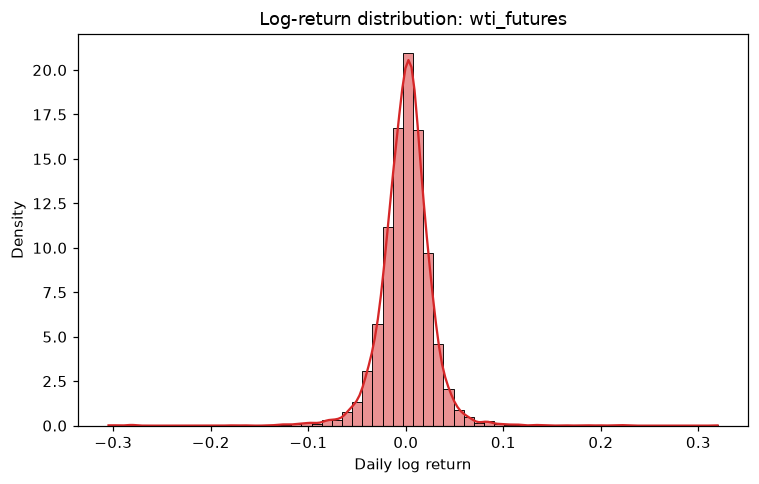

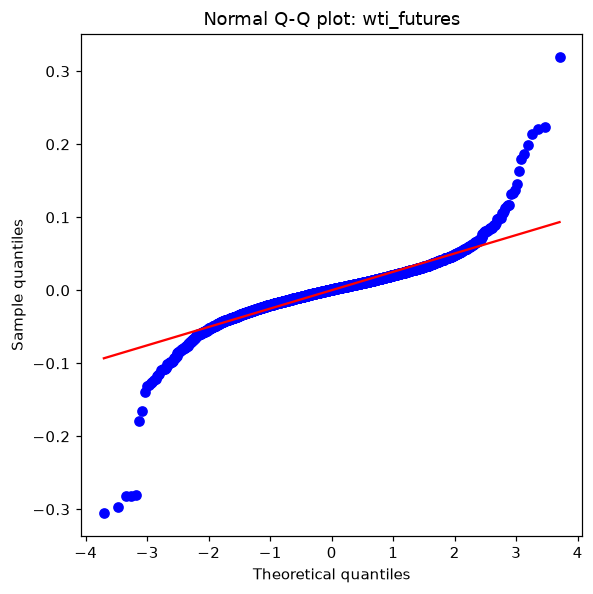

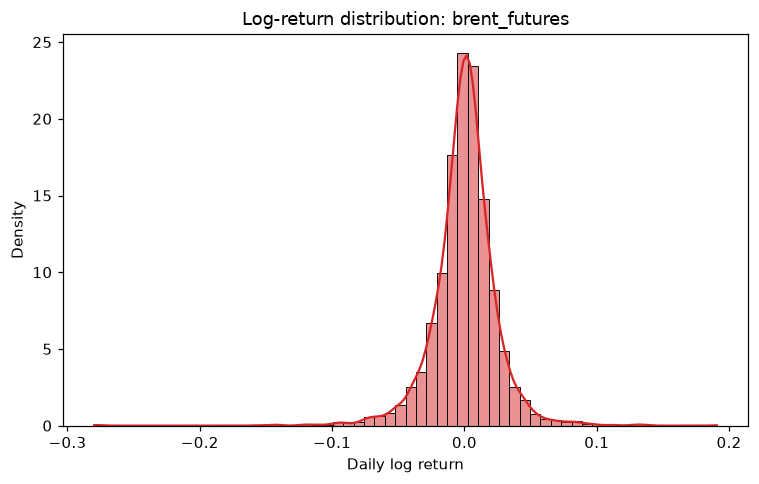

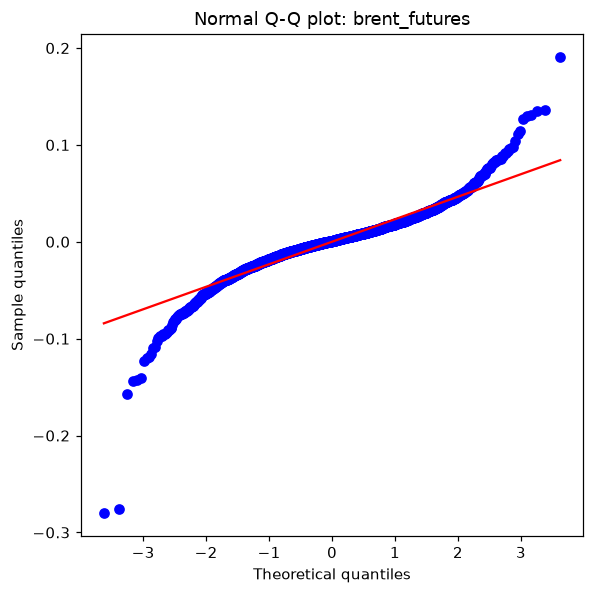

In [6]:
dist_plotter = DistributionPlotter()
HEADLINE_SERIES = ["wti_futures", "brent_futures"]

for name, series in sorted(cleaned_series.items()):
    fig = dist_plotter.plot_histogram(
        series, units=units_by_name.get(name, ""), save_path=FIGURES_DIR / f"hist_{name}.png"
    )
    plt.close(fig)
print(f"Saved {len(cleaned_series)} histograms to {FIGURES_DIR}")

for name in HEADLINE_SERIES:
    fig = dist_plotter.plot_return_distribution(
        cleaned_series[name], save_path=FIGURES_DIR / f"return_dist_{name}.png"
    )
    plt.show()
    log_returns = np.log(cleaned_series[name] / cleaned_series[name].shift(1)).dropna()
    fig = dist_plotter.plot_qq(log_returns, save_path=FIGURES_DIR / f"qq_{name}.png")
    plt.show()

## Step 7 — Exploratory data analysis: time series plots (Step 7b, Student B)

A level plot is generated and saved for every one of the 24 series (ALL
datasets). Rolling volatility and ACF/PACF are additionally computed for
the two crude benchmarks, since clustered volatility and autocorrelation
of *returns* are the stylized facts the group must comment on in Step 8 —
computing them on a non-traded macro level series (e.g. OPEC spare
capacity in mb/d) would not be a meaningful "volatility of returns"
statistic.

Saved 24 level plots to c:\Users\fdeba001\Downloads\WQU\oil-price-risk-capstone\reports\GWP1\figures


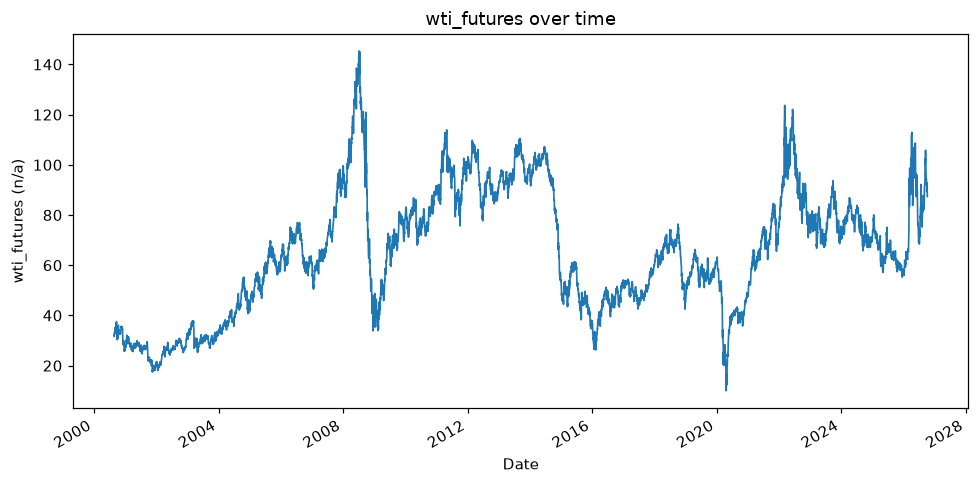

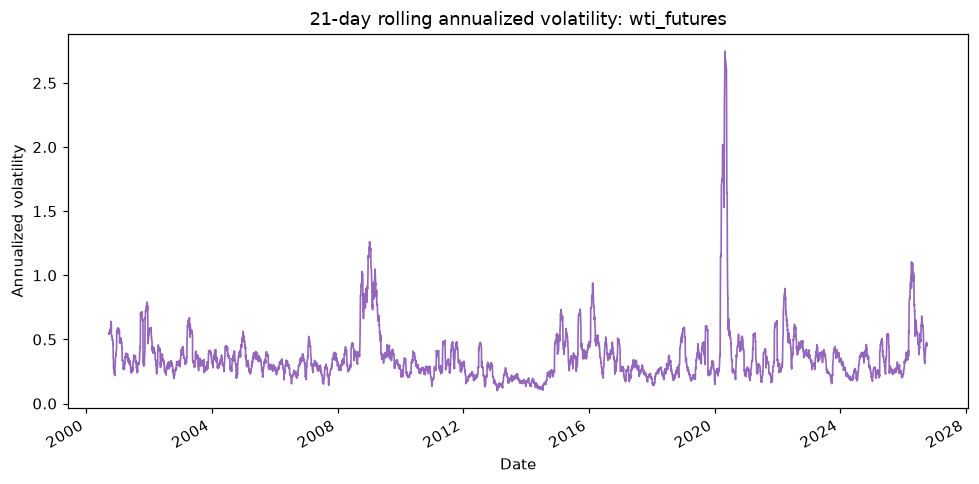

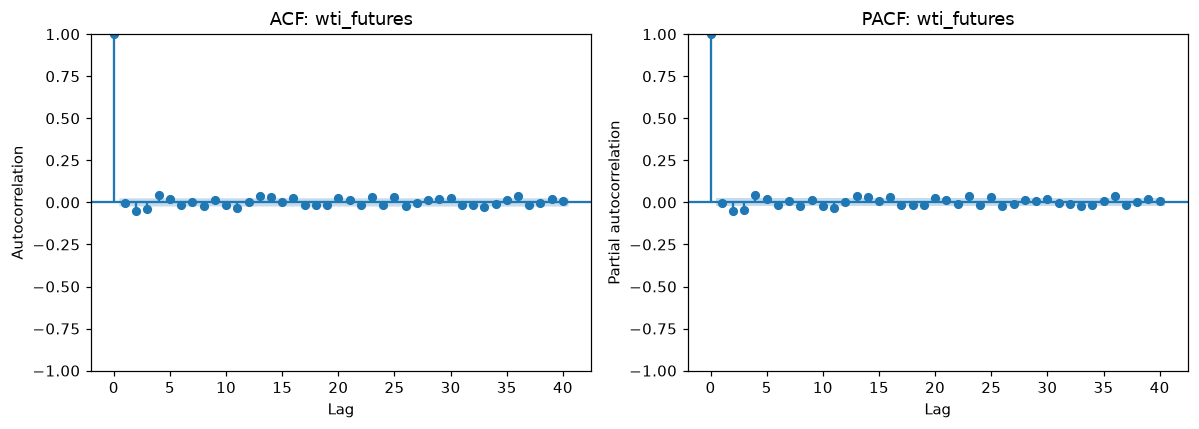

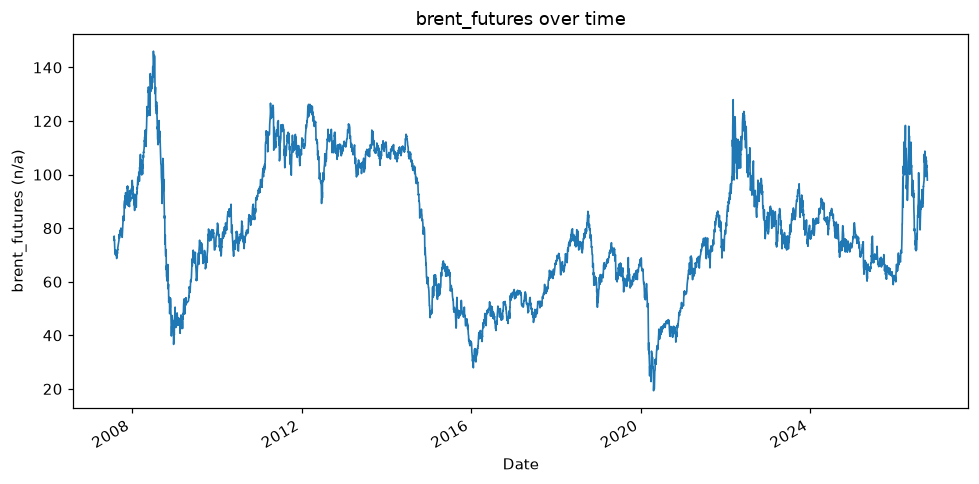

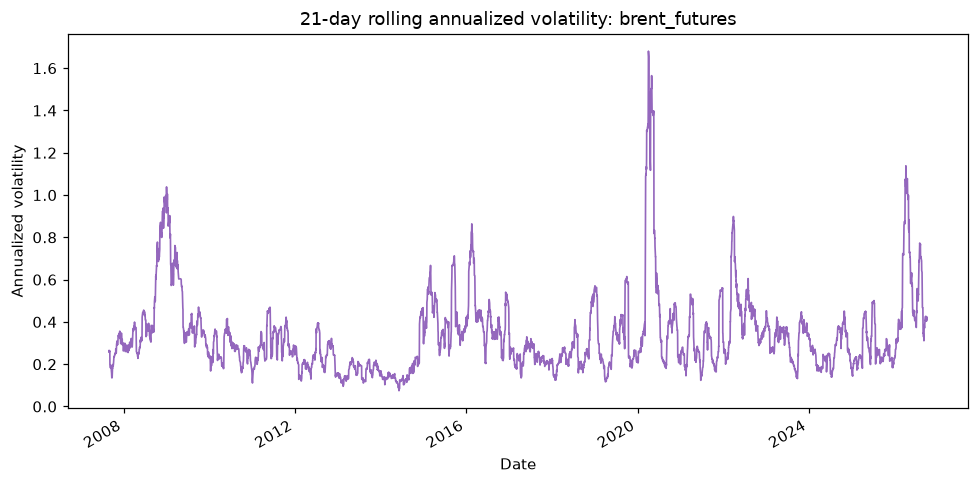

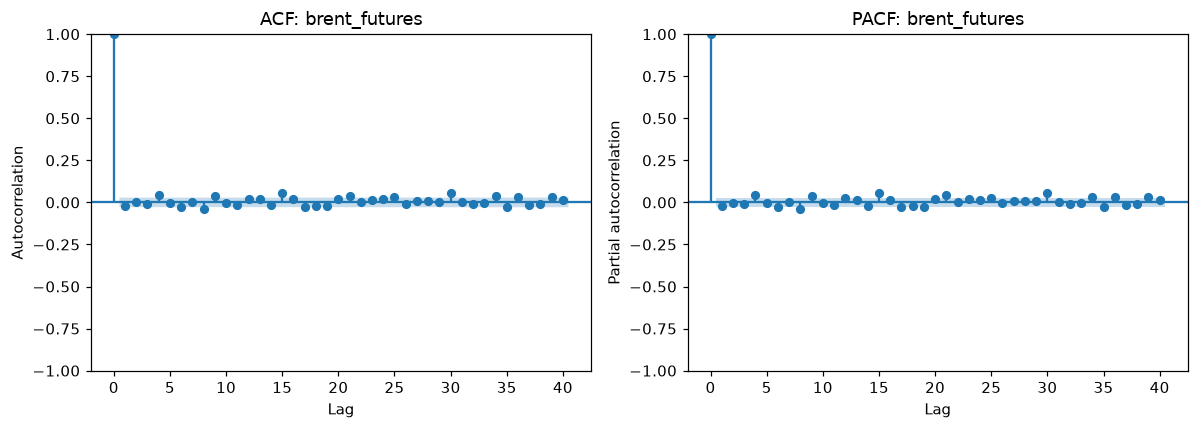

In [7]:
ts_plotter = TimeSeriesPlotter()

for name, series in sorted(cleaned_series.items()):
    fig = ts_plotter.plot_level(
        series, units=units_by_name.get(name, ""), save_path=FIGURES_DIR / f"level_{name}.png"
    )
    plt.close(fig)
print(f"Saved {len(cleaned_series)} level plots to {FIGURES_DIR}")

for name in HEADLINE_SERIES:
    fig = ts_plotter.plot_level(
        cleaned_series[name],
        units=units_by_name.get(name, ""),
        save_path=FIGURES_DIR / f"level_deep_{name}.png",
    )
    plt.show()
    fig = ts_plotter.plot_rolling_volatility(
        cleaned_series[name], save_path=FIGURES_DIR / f"vol_{name}.png"
    )
    plt.show()
    log_returns = np.log(cleaned_series[name] / cleaned_series[name].shift(1)).dropna()
    fig = ts_plotter.plot_autocorrelation(log_returns, save_path=FIGURES_DIR / f"acf_{name}.png")

## Step 8 — Exploratory data analysis: multivariate plots (Step 7c, Student C)

Three complementary multivariate views, each covering the full panel in
a different way so that "ALL datasets" are represented somewhere in this
section:

1. A single correlation heatmap across **all 24** monthly-aligned series
   (the most compact way to show every pairwise relationship at once).
2. A rolling correlation between WTI and the USD index — the textbook
   oil/dollar inverse-relationship stylized fact — computed at native
   daily frequency.
3. A scatter-matrix of a curated subset of headline variables (the two
   crude benchmarks plus one representative from each other group) for
   a readable, non-overplotted view; a 24-variable pairplot would be both
   illegible and very slow to render.

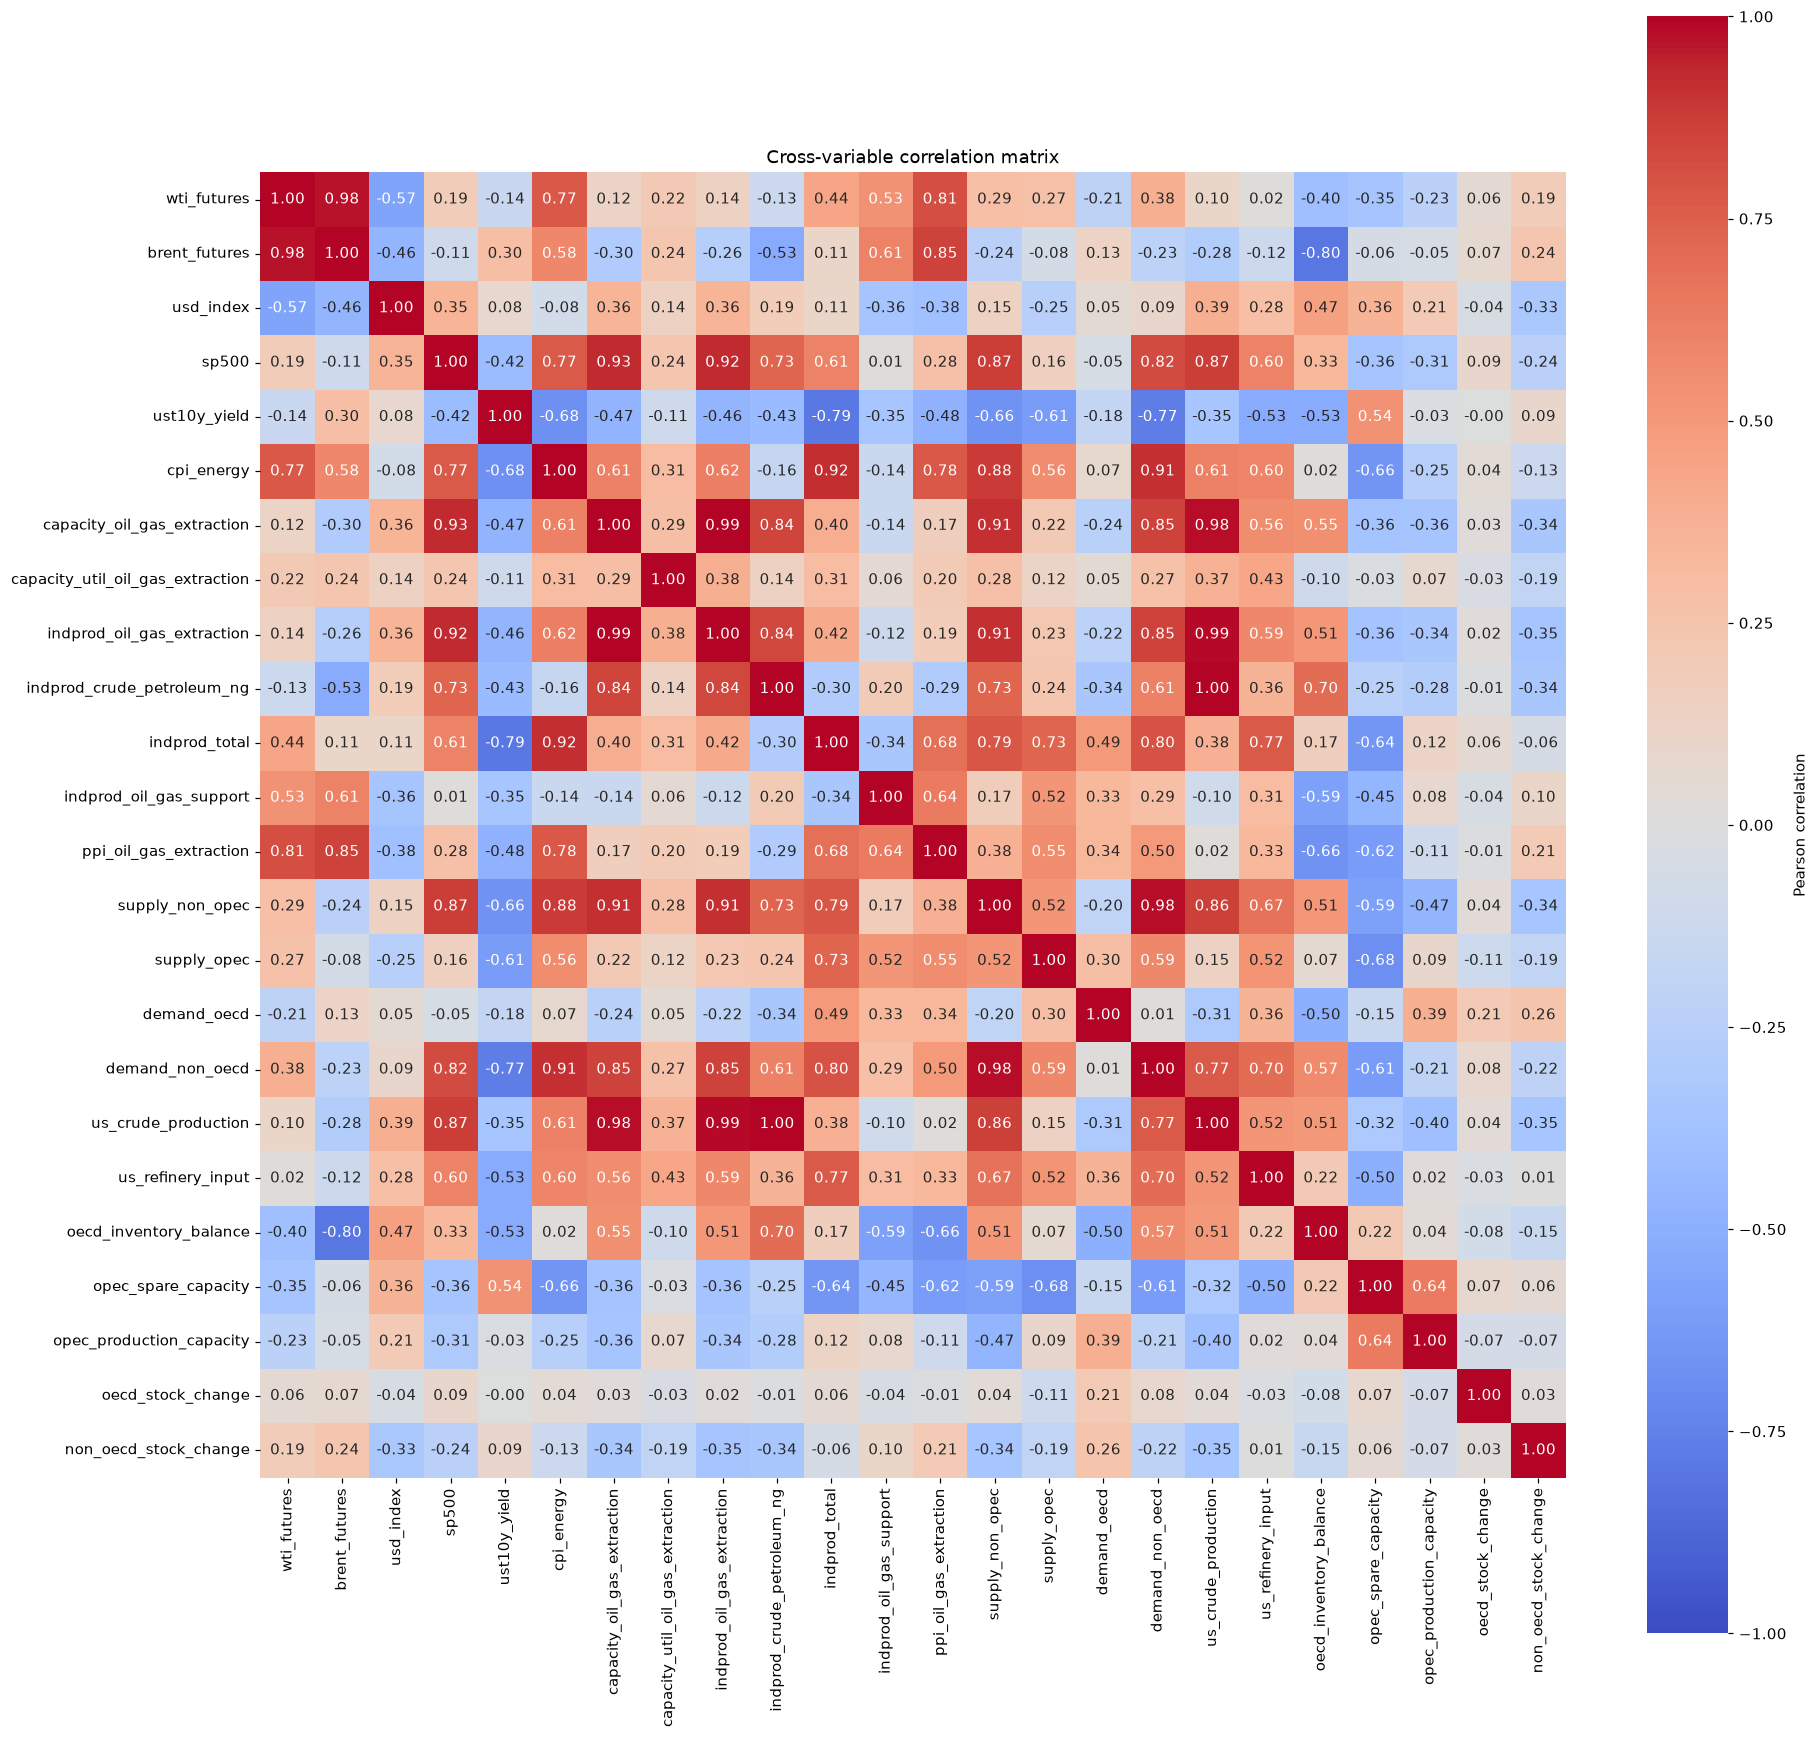

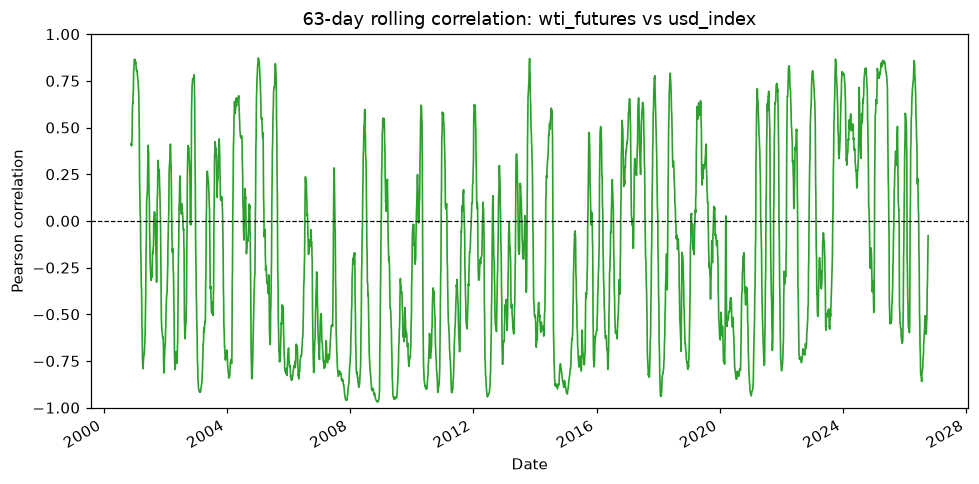

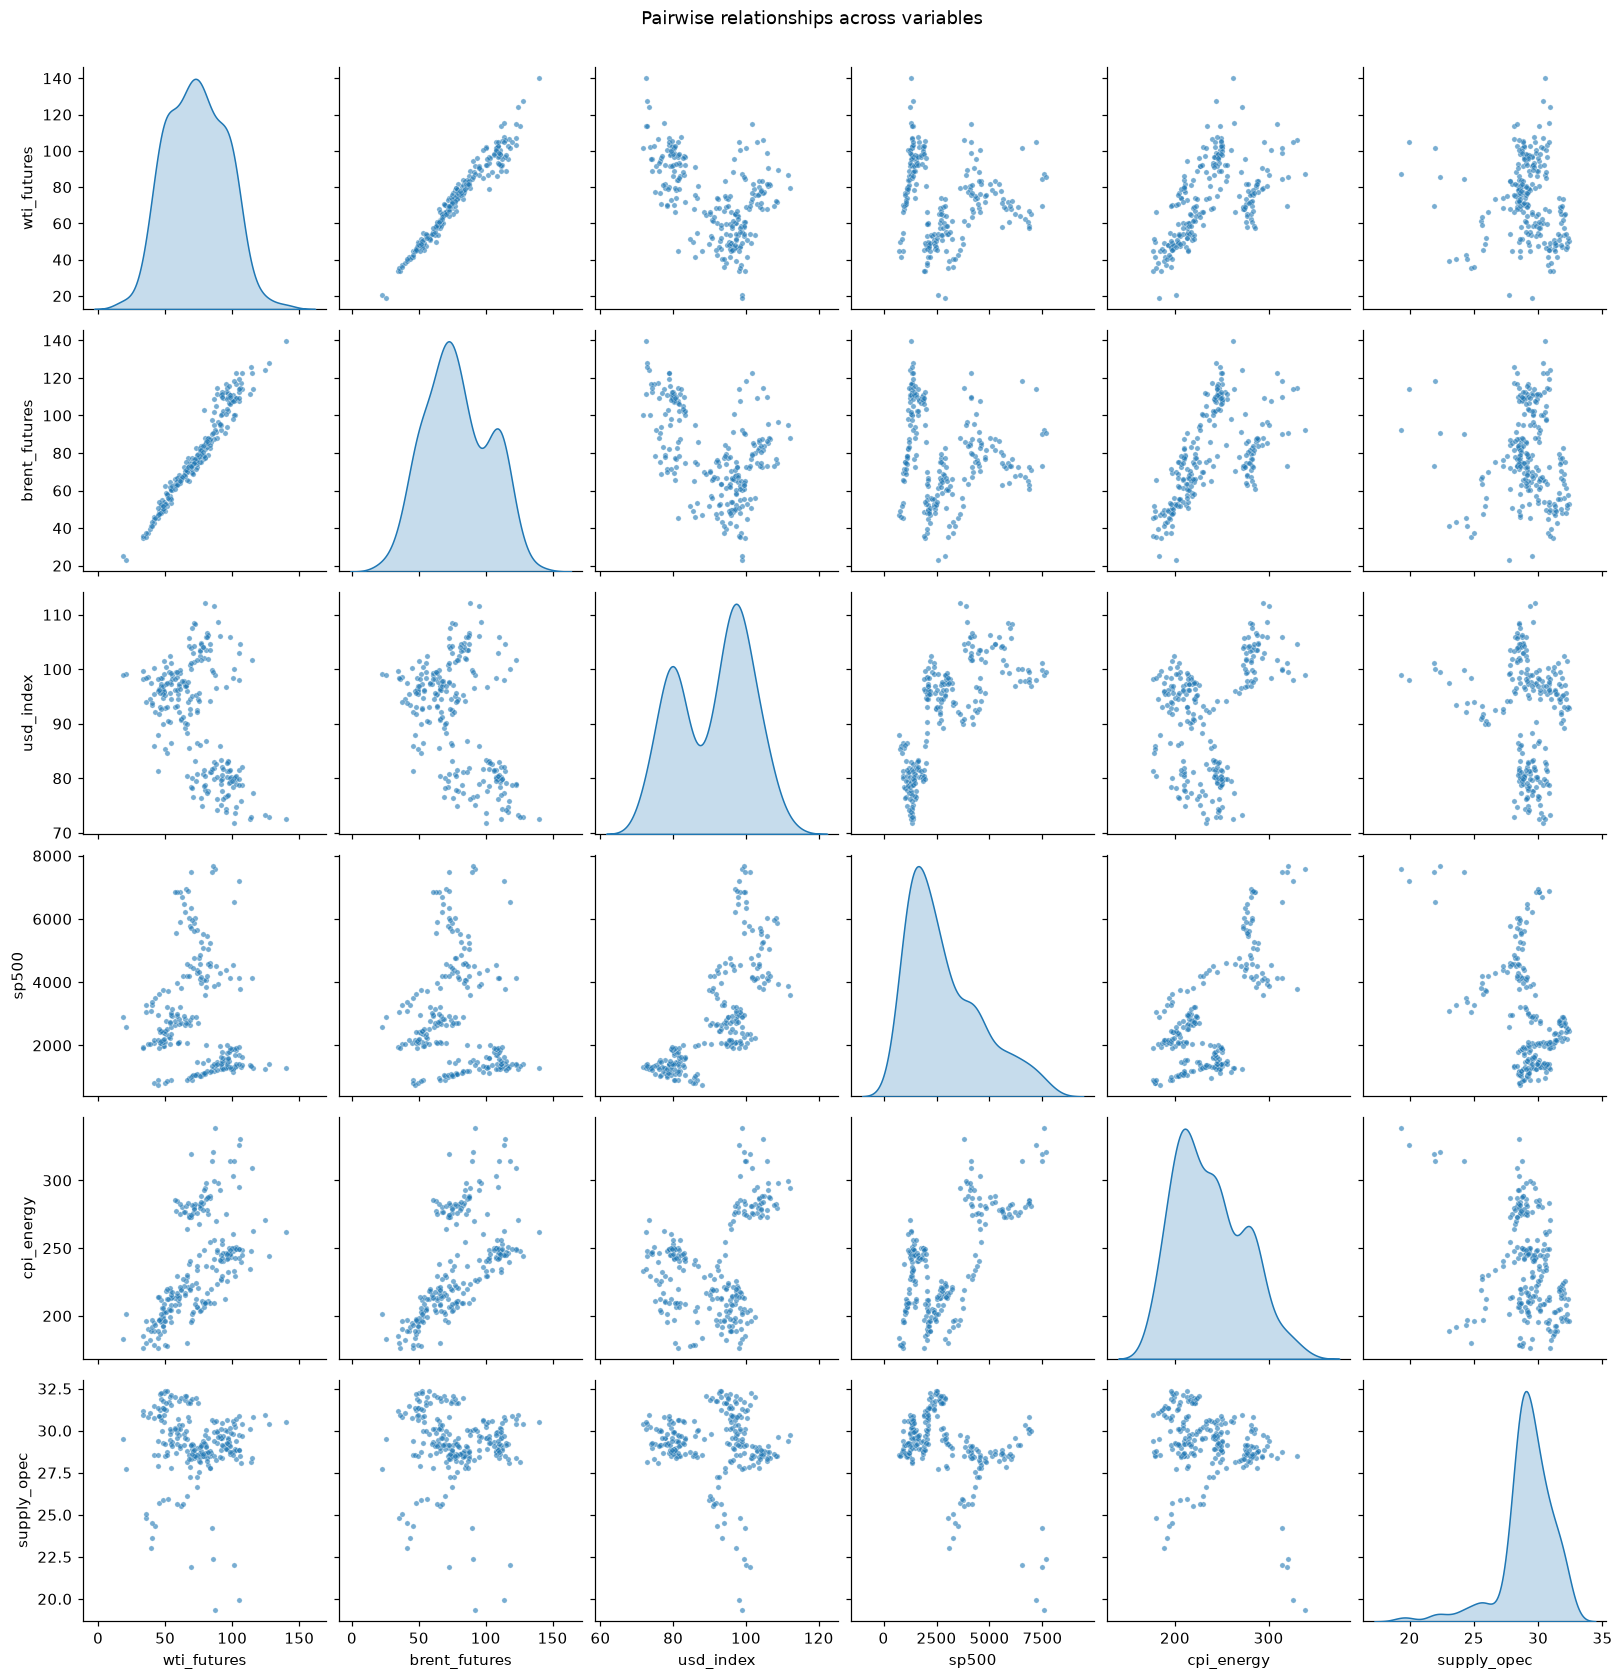

In [9]:
mv_plotter = MultivariatePlotter()

fig = mv_plotter.plot_correlation_heatmap(
    panel_monthly, save_path=FIGURES_DIR / "correlation_heatmap_all.png"
)
plt.show()

fig = mv_plotter.plot_rolling_correlation(
    cleaned_series["wti_futures"],
    cleaned_series["usd_index"],
    save_path=FIGURES_DIR / "rolling_corr_wti_usd.png",
)
plt.show()

SCATTER_SUBSET = [
    "wti_futures",
    "brent_futures",
    "usd_index",
    "sp500",
    "cpi_energy",
    "supply_opec",
]
fig = mv_plotter.plot_scatter_matrix(
    panel_monthly[SCATTER_SUBSET],
    save_path=FIGURES_DIR / "scatter_matrix_headline.png",
)
plt.show()

## Step 9 — Stylized facts (Step 8 of the assignment): compute the evidence

Before answering the four stylized-facts questions in prose, compute the
actual numbers the answers must be grounded in: skewness, excess kurtosis,
and the Jarque-Bera normality test on daily log returns for both crude
benchmarks, plus the ACF of squared returns (the standard volatility-
clustering diagnostic, as opposed to the ACF of raw returns which tests
for return *predictability*).

In [10]:
from scipy import stats
from statsmodels.tsa.stattools import acf

stylized_fact_stats = {}
for name in HEADLINE_SERIES:
    log_returns = np.log(cleaned_series[name] / cleaned_series[name].shift(1)).dropna()
    jb_stat, jb_pvalue = stats.jarque_bera(log_returns)
    squared_returns = log_returns**2
    acf_returns = acf(log_returns, nlags=10, fft=True)
    acf_squared = acf(squared_returns, nlags=10, fft=True)
    stylized_fact_stats[name] = {
        "n_obs": len(log_returns),
        "mean_annualized": log_returns.mean() * 252,
        "vol_annualized": log_returns.std() * np.sqrt(252),
        "skewness": stats.skew(log_returns),
        "excess_kurtosis": stats.kurtosis(log_returns),
        "jarque_bera_stat": jb_stat,
        "jarque_bera_pvalue": jb_pvalue,
        "acf_returns_lag1": acf_returns[1],
        "acf_squared_returns_lag1": acf_squared[1],
        "acf_squared_returns_lag5": acf_squared[5],
    }

stats_frame = pd.DataFrame(stylized_fact_stats).T
stats_frame

,n_obs,mean_annualized,vol_annualized,skewness,excess_kurtosis,jarque_bera_stat,jarque_bera_pvalue,acf_returns_lag1,acf_squared_returns_lag1,acf_squared_returns_lag5
wti_futures,6557.0,0.038533,0.425584,-0.508470,18.741373,96243.98022,0.0,-0.004386,0.459592,0.249500
brent_futures,4775.0,0.013566,0.386578,-0.772662,11.627560,27374.31481,0.0,-0.018428,0.203743,0.124016


## Step 10 — Stylized facts: answers (Step 8 of the assignment)

**(a) What makes oil prices look different from other asset prices (e.g.
spikes, clustered volatility, seasonality)?** The level plots above show
oil behaving less like a smoothly-trending equity index and more like a
regime-switching series: multi-year bull/bear swings (2000-08 rally,
2008-09 collapse, 2014-16 collapse, 2020 COVID crash, 2022 Ukraine spike)
punctuated by sharp, short-lived spikes. The `21-day rolling annualized
volatility` plots show volatility itself is clustered and regime-dependent
— calm multi-year stretches below 0.3 annualized vol interrupted by
violent spikes above 1.0 (2008, 2020) and even above 2.5 for WTI in April
2020. That April 2020 episode is itself a uniquely oil-specific
phenomenon: WTI's spot/near-month price briefly went **negative** (observed
as a single non-positive data point in the raw feed), something that is
essentially impossible for an equity or FX price but can happen for a
physically-settled commodity future when storage capacity is exhausted
and longs cannot take delivery. Our `BadDataCleaner` treats any
non-positive price as data error by design (a defensible general-purpose
rule), so that specific historic value was imputed away in the
"sterilized" series used for the plots above — a transparent, documented
methodological trade-off rather than a silent one, and worth flagging as
a genuine stylized fact even though it is not visible in the cleaned data.

**(b) What type of distribution do oil returns have?** Far from Normal.
For WTI: skewness = -0.51 (mild negative/left skew — large down-moves are
somewhat more extreme than large up-moves) and **excess kurtosis = 18.7**
(vs. 0 for a Normal distribution), i.e. strongly leptokurtic / fat-tailed.
Brent shows the same pattern (skewness -0.77, excess kurtosis 11.6). The
Jarque-Bera test rejects normality overwhelmingly for both
(JB = 96,264 and 27,389 respectively, p ≈ 0 in both cases), consistent
with the pronounced tail curvature visible in the Q-Q plots above (sample
quantiles bow sharply away from the theoretical Normal line beyond
±2 standard deviations).

**(c) What type of autocorrelation do oil returns have?** Essentially
none at the *level* of raw returns: lag-1 autocorrelation is -0.004 for
WTI and -0.018 for Brent, and the ACF/PACF plots show no significant
spikes beyond lag 0 — consistent with (weak-form) market efficiency, i.e.
the sign/direction of tomorrow's return is not linearly predictable from
today's. However, the *squared* returns tell a very different story:
lag-1 autocorrelation of squared returns is 0.46 (WTI) and 0.20 (Brent),
still 0.25 / 0.12 at lag 5 — strong, slowly-decaying autocorrelation.
This is the textbook signature of **volatility clustering**: returns
themselves are unpredictable, but the *magnitude* of returns is highly
persistent (large moves are followed by large moves, of either sign).

**(d) What other stylized facts can you say about oil prices?** (i) A
**negative, but highly unstable, correlation with the US dollar index**:
the full-sample level correlation is -0.57 (WTI) / -0.46 (Brent), yet the
63-day rolling-correlation plot oscillates repeatedly between roughly
-1 and +1 across the whole 2000-2026 history with no single stable
regime — the textbook "stronger dollar, cheaper oil" relationship holds
*on average* but is far too unstable to use as a reliable short-horizon
hedge on its own. (ii) **Co-movement between benchmarks**: WTI and Brent
correlate at 0.98 in levels and track each other almost one-for-one in
the scatter matrix, as expected for two prices of the same underlying
global commodity linked by arbitrage (shipping/quality spread aside).
(iii) Oil correlates positively, but only moderately, with broad
inflation/risk-sentiment variables — the CPI energy index (0.77 WTI,
0.58 Brent) more so than the S&P 500 (0.19 WTI, -0.11 Brent) — i.e.
energy prices are a meaningful *component* of realised inflation, not
merely a passive responder to broad equity risk sentiment. (iv)
Geopolitical/supply variables correlate only weakly and inconsistently
with price (e.g. OPEC supply: 0.27 WTI / -0.08 Brent; non-OPEC supply:
0.29 WTI / -0.24 Brent) — far weaker than the financial variables above —
consistent with Alvi's core thesis that oil-price dynamics are better
captured by a *non-linear*, graphical/probabilistic model of many
interacting physical and financial drivers than by simple pairwise linear
correlation.

## Summary and artifacts produced

This notebook has executed GWP1 assignment Steps 3-8 end-to-end against
real financial, macroeconomic, and EIA geopolitical/physical-market data
(24 series total, no synthetic fallbacks were needed given the configured
API keys). Artifacts written to disk for direct inclusion in the LaTeX
report (`reports/GWP1/main.tex`) and for reuse in GWP2/GWP3:

- `reports/GWP1/tables/data_dictionary.tex` + `data/processed/data_dictionary.csv`
  — Step 4 data dictionary (24 rows).
- `reports/GWP1/sections/cleaning_narrative.tex` — Steps 5-6 cleaning
  narrative (52 logged actions across the 24 series).
- `reports/GWP1/figures/*.png` — Step 7 distributional (24 histograms + 2
  return-distribution/Q-Q deep dives), time series (24 level plots + 2
  volatility/ACF deep dives), and multivariate (1 full correlation
  heatmap, 1 rolling correlation, 1 scatter matrix) figures.
- `data/processed/gwp1_monthly_panel.csv` — the combined, cleaned,
  month-end-aligned panel used for the multivariate analysis.
- `data/processed/{series_name}.csv` — each cleaned series at its native
  frequency, for GWP2's Bayesian-network and HMM modeling.

**Next steps** (outside this notebook): write up `reports/GWP1/main.tex`
(problem formulation, PGM/Markov-blanket role summaries, and the group's
own pseudocode for Alvi's Algorithm 1 "Inferred Causality"), compile it
to PDF, and only then begin GWP2 (HMM regime-switching model implemented
from scratch in NumPy, and a Bayesian network learned via `pgmpy`'s
Hill-Climbing search over this same cleaned panel).